In [1]:
import json
import os
import pandas as pd
import warnings; warnings.filterwarnings('ignore')

RAW_DATA_PATH = "../data/raw/ipl_json"
PROCESSED_DATA_PATH = "../data/processed"

os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

matches = []

for file in os.listdir(RAW_DATA_PATH):
    if file.endswith(".json"):
        with open(os.path.join(RAW_DATA_PATH, file), "r", encoding="utf-8") as f:
            match = json.load(f)

        info = match["info"]

        record = {
            "match_id": file.replace(".json", ""),
            "season": info.get("season"),
            "venue": info.get("venue"),
            "team_1": info["teams"][0],
            "team_2": info["teams"][1],
            "toss_winner": info["toss"]["winner"],
            "toss_decision": info["toss"]["decision"],
            "winner": info.get("outcome", {}).get("winner")
        }

        matches.append(record)

df_matches = pd.DataFrame(matches)

df_matches


,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore
...,...,...,...,...,...,...,...,...
1164,981011,2016,Shaheed Veer Narayan Singh International Stadium,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Royal Challengers Bangalore
1165,981013,2016,M Chinnaswamy Stadium,Gujarat Lions,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Royal Challengers Bangalore
1166,981015,2016,Feroz Shah Kotla,Sunrisers Hyderabad,Kolkata Knight Riders,Kolkata Knight Riders,field,Sunrisers Hyderabad
1167,981017,2016,Feroz Shah Kotla,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Sunrisers Hyderabad


In [2]:
df_matches.to_csv("../data/processed/matches.csv", index=False)

In [3]:

df_matches_clean = df_matches[df_matches["winner"].notna()].copy()

print("Before cleaning:", df_matches.shape)
print("After cleaning :", df_matches_clean.shape)


Before cleaning: (1169, 8)
After cleaning : (1146, 8)


In [4]:
def get_first_innings_runs(match_json):
    innings = match_json.get("innings", [])
    
    # Safety check
    if len(innings) == 0:
        return None
    
    first_innings = innings[0]
    total_runs = 0

    for over in first_innings.get("overs", []):
        for delivery in over.get("deliveries", []):
            total_runs += delivery.get("runs", {}).get("total", 0)

    return total_runs

In [5]:
first_innings_scores = []

for file in os.listdir(RAW_DATA_PATH):
    if file.endswith(".json"):
        with open(os.path.join(RAW_DATA_PATH, file), "r", encoding="utf-8") as f:
            match = json.load(f)

        match_id = file.replace(".json", "")
        runs = get_first_innings_runs(match)

        first_innings_scores.append({
            "match_id": match_id,
            "first_innings_runs": runs
        })

df_scores = pd.DataFrame(first_innings_scores)
df_scores.head()

,match_id,first_innings_runs
0,1082591,207
1,1082592,184
2,1082593,183
3,1082594,163
4,1082595,157


In [6]:
df_final = df_matches_clean.merge(
    df_scores,
    on="match_id",
    how="left"
)

df_final.head()

,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner,first_innings_runs
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,184
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,183
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,163
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157


In [7]:
df_final.isna().sum()

match_id              0
season                0
venue                 0
team_1                0
team_2                0
toss_winner           0
toss_decision         0
winner                0
first_innings_runs    0
dtype: int64

In [8]:
df_final.shape

(1146, 9)

In [9]:
df_final.head()

,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner,first_innings_runs
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,184
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,183
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,163
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157


In [10]:
df_final.isna().sum()

match_id              0
season                0
venue                 0
team_1                0
team_2                0
toss_winner           0
toss_decision         0
winner                0
first_innings_runs    0
dtype: int64

In [11]:
toss_win_rate = (df_final["toss_winner"] == df_final["winner"]).mean()
toss_win_rate

0.5157068062827225

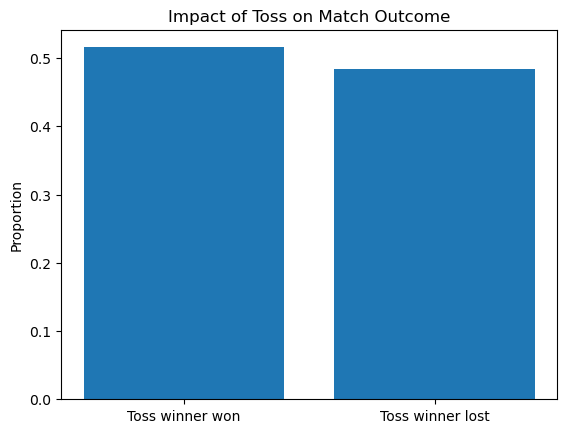

In [12]:
import matplotlib.pyplot as plt

labels = ["Toss winner won", "Toss winner lost"]
values = [toss_win_rate, 1 - toss_win_rate]

plt.bar(labels, values)
plt.ylabel("Proportion")
plt.title("Impact of Toss on Match Outcome")
plt.show()

In [13]:
df_final["batting_first_team"] = df_final.apply(
    lambda row: (
        row["toss_winner"]
        if row["toss_decision"] == "bat"
        else (
            row["team_2"]
            if row["toss_winner"] == row["team_1"]
            else row["team_1"]
        )
    ),
    axis=1
)
df_final["bat_first_won"] = (
    df_final["batting_first_team"] == df_final["winner"]
)
df_final.head()

,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner,first_innings_runs,batting_first_team,bat_first_won
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207,Sunrisers Hyderabad,True
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,184,Mumbai Indians,False
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,183,Gujarat Lions,False
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,163,Rising Pune Supergiant,False
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157,Royal Challengers Bangalore,True


In [14]:
bat_first_win_rate = df_final["bat_first_won"].mean()
bat_first_win_rate

0.4581151832460733

In [15]:
df_final["strategy"] = df_final.apply(
    lambda row: "Bat First"
    if row["batting_first_team"] == row["team_1"]
    else "Chase",
    axis=1
)
df_final["team1_win"] = (df_final["winner"] == df_final["team_1"]).astype(int)
df_final.head()

,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner,first_innings_runs,batting_first_team,bat_first_won,strategy,team1_win
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207,Sunrisers Hyderabad,True,Bat First,1
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,184,Mumbai Indians,False,Chase,1
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,183,Gujarat Lions,False,Bat First,0
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,163,Rising Pune Supergiant,False,Chase,1
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157,Royal Challengers Bangalore,True,Bat First,1


In [16]:
strategy_win_rate = (
    df_final
    .groupby("strategy")["bat_first_won"]
    .mean()
    .reset_index()
)

strategy_win_rate

,strategy,bat_first_won
0,Bat First,0.476526
1,Chase,0.404762


In [17]:
strategy_win_rate["win_percentage"] = strategy_win_rate["bat_first_won"] * 100
strategy_win_rate

,strategy,bat_first_won,win_percentage
0,Bat First,0.476526,47.652582
1,Chase,0.404762,40.476190


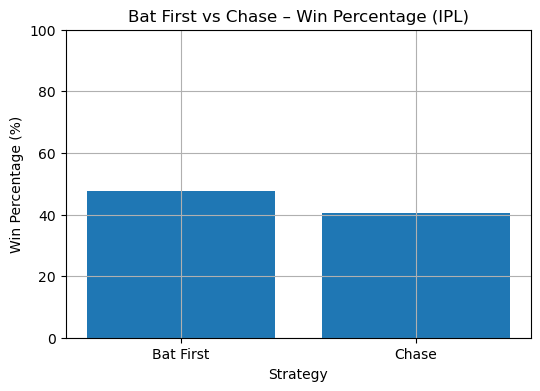

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(
    strategy_win_rate["strategy"],
    strategy_win_rate["win_percentage"]
)

plt.ylabel("Win Percentage (%)")
plt.xlabel("Strategy")
plt.title("Bat First vs Chase – Win Percentage (IPL)")

plt.ylim(0, 100)
plt.grid()
plt.show()

In [19]:
bins = [0, 120, 140, 160, 180, 200, 300]
labels = ["<120", "120-140", "140-160", "160-180", "180-200", "200+"]

df_final["score_bucket"] = pd.cut(
    df_final["first_innings_runs"],
    bins=bins,
    labels=labels
)
df_final.head() 

,match_id,season,venue,team_1,team_2,toss_winner,toss_decision,winner,first_innings_runs,batting_first_team,bat_first_won,strategy,team1_win,score_bucket
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,Sunrisers Hyderabad,207,Sunrisers Hyderabad,True,Bat First,1,200+
1,1082592,2017,Maharashtra Cricket Association Stadium,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,field,Rising Pune Supergiant,184,Mumbai Indians,False,Chase,1,180-200
2,1082593,2017,Saurashtra Cricket Association Stadium,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,Kolkata Knight Riders,183,Gujarat Lions,False,Bat First,0,180-200
3,1082594,2017,Holkar Cricket Stadium,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,field,Kings XI Punjab,163,Rising Pune Supergiant,False,Chase,1,160-180
4,1082595,2017,M.Chinnaswamy Stadium,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,Royal Challengers Bangalore,157,Royal Challengers Bangalore,True,Bat First,1,140-160


In [20]:
score_win_rate = (
    df_final
    .groupby("score_bucket")["bat_first_won"]
    .mean()
    .reset_index()
)

score_win_rate["win_percentage"] = score_win_rate["bat_first_won"] * 100
score_win_rate

,score_bucket,bat_first_won,win_percentage
0,<120,0.087912,8.791209
1,120-140,0.242424,24.242424
2,140-160,0.289256,28.925620
3,160-180,0.488372,48.837209
4,180-200,0.617925,61.792453
5,200+,0.815476,81.547619


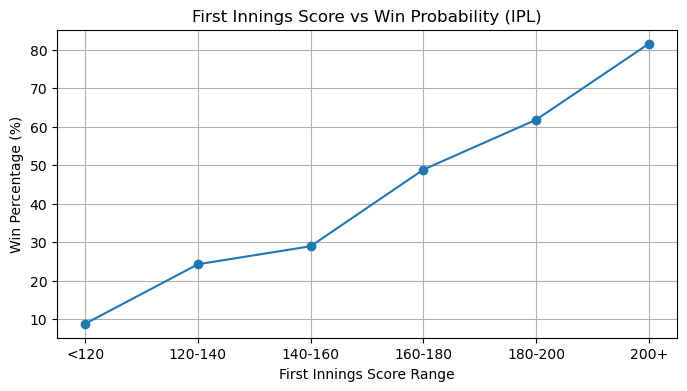

In [21]:
plt.figure(figsize=(8,4))

plt.plot(
    score_win_rate["score_bucket"],
    score_win_rate["win_percentage"],
    marker="o"
)

plt.xlabel("First Innings Score Range")
plt.ylabel("Win Percentage (%)")
plt.title("First Innings Score vs Win Probability (IPL)")
plt.grid()
plt.show()

In [22]:
df_final["chasing_team"] = df_final.apply(
    lambda row: row["team_2"]
    if row["batting_first_team"] == row["team_1"]
    else row["team_1"],
    axis=1
)

In [23]:
df_final["chase_win"] = (
    df_final["winner"] != df_final["batting_first_team"]
).astype(int)

In [24]:
df_final[[
    "batting_first_team",
    "chasing_team",
    "winner",
    "chase_win"
]].head()

,batting_first_team,chasing_team,winner,chase_win
0,Sunrisers Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,0
1,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,1
2,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,1
3,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,1
4,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,0


In [25]:
X = df_final[
    [
        "batting_first_team",
        "chasing_team",
        "venue",
        "first_innings_runs"
    ]
]
y = df_final["chase_win"]
X.head()

,batting_first_team,chasing_team,venue,first_innings_runs
0,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",207
1,Mumbai Indians,Rising Pune Supergiant,Maharashtra Cricket Association Stadium,184
2,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,183
3,Rising Pune Supergiant,Kings XI Punjab,Holkar Cricket Stadium,163
4,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,157


In [26]:
X_encoded = pd.get_dummies(X, drop_first=True)

In [27]:
training_columns = X_encoded.columns

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.25,
    random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)


RandomForestClassifier(max_depth=10, n_estimators=300, random_state=42)

In [29]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7003484320557491
              precision    recall  f1-score   support

           0       0.71      0.64      0.67       138
           1       0.69      0.76      0.72       149

    accuracy                           0.70       287
   macro avg       0.70      0.70      0.70       287
weighted avg       0.70      0.70      0.70       287



In [30]:
import pandas as pd
import numpy as np

def predict_chase_outcome(
    batting_first_team,
    chasing_team,
    venue,
    first_innings_runs,
    model,
    training_columns
):
    """
    Predict whether the chasing team will win an IPL match.
    """

    # Step 1: Create input DataFrame
    input_df = pd.DataFrame([{
        "batting_first_team": batting_first_team,
        "chasing_team": chasing_team,
        "venue": venue,
        "first_innings_runs": first_innings_runs
    }])

    # Step 2: One-hot encode
    input_encoded = pd.get_dummies(input_df)

    # Step 3: Align with training columns
    input_encoded = input_encoded.reindex(
        columns=training_columns,
        fill_value=0
    )

    # Step 4: Predict
    pred = model.predict(input_encoded)[0]
    prob = model.predict_proba(input_encoded)[0][1]

    # Step 5: Interpret result
    if pred == 1:
        result = f"🏆 Chasing team ({chasing_team}) is likely to WIN"
    else:
        result = f"❌ Chasing team ({chasing_team}) is likely to LOSE"

    return {
        "prediction": pred,
        "result": result,
        "win_probability": round(prob * 100, 2)
    }

In [31]:
output = predict_chase_outcome(
    batting_first_team="Chennai Super Kings",
    chasing_team="Mumbai Indians",
    venue="Wankhede Stadium",
    first_innings_runs=185,
    model=rf_model,
    training_columns=training_columns
)

print(output["result"])
print(f"Win Probability: {output['win_probability']}%")

❌ Chasing team (Mumbai Indians) is likely to LOSE
Win Probability: 49.95%


In [32]:
predict_chase_outcome(
    batting_first_team="Rajasthan Royals",
    chasing_team="Punjab Kings",
    venue="Sawai Mansingh Stadium",
    first_innings_runs=145,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 1,
 'result': '🏆 Chasing team (Punjab Kings) is likely to WIN',
 'win_probability': 70.23}

In [33]:
predict_chase_outcome(
    batting_first_team="Delhi Capitals",
    chasing_team="Mumbai Indians",
    venue="Wankhede Stadium",
    first_innings_runs=205,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 0,
 'result': '❌ Chasing team (Mumbai Indians) is likely to LOSE',
 'win_probability': 42.53}

In [34]:
predict_chase_outcome(
    batting_first_team="Sunrisers Hyderabad",
    chasing_team="Royal Challengers Bangalore",
    venue="MA Chidambaram Stadium",
    first_innings_runs=175,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 1,
 'result': '🏆 Chasing team (Royal Challengers Bangalore) is likely to WIN',
 'win_probability': 54.43}

In [35]:
predict_chase_outcome(
    batting_first_team="Kolkata Knight Riders",
    chasing_team="Gujarat Titans",
    venue="Narendra Modi Stadium",
    first_innings_runs=120,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 1,
 'result': '🏆 Chasing team (Gujarat Titans) is likely to WIN',
 'win_probability': 71.33}

In [36]:
predict_chase_outcome(
    batting_first_team="Lucknow Super Giants",
    chasing_team="Chennai Super Kings",
    venue="Ekana Cricket Stadium",
    first_innings_runs=165,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 1,
 'result': '🏆 Chasing team (Chennai Super Kings) is likely to WIN',
 'win_probability': 54.44}

In [37]:
predict_chase_outcome(
    batting_first_team="Mumbai Indians",
    chasing_team="Chennai Super Kings",
    venue="Wankhede Stadium",
    first_innings_runs=180,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 0,
 'result': '❌ Chasing team (Chennai Super Kings) is likely to LOSE',
 'win_probability': 42.44}

In [1]:
predict_chase_outcome(
    batting_first_team="Mumbai Indians",
    chasing_team="Chennai Super Kings",
    venue="MA Chidambaram Stadium",
    first_innings_runs=180,
    model=rf_model,
    training_columns=training_columns
)

NameError: name 'predict_chase_outcome' is not defined

In [39]:
predict_chase_outcome(
    batting_first_team="Gujarat Titans",
    chasing_team="Lucknow Super Giants",
    venue="Narendra Modi Stadium",
    first_innings_runs=190,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 0,
 'result': '❌ Chasing team (Lucknow Super Giants) is likely to LOSE',
 'win_probability': 40.5}

In [40]:
predict_chase_outcome(
    batting_first_team="Sunrisers Hyderabad",
    chasing_team="Mumbai Indians",
    venue="Rajiv Gandhi International Stadium",
    first_innings_runs=240,
    model=rf_model,
    training_columns=training_columns
)

{'prediction': 0,
 'result': '❌ Chasing team (Mumbai Indians) is likely to LOSE',
 'win_probability': 35.2}

In [41]:


importances = rf_model.feature_importances_


feature_importance_df = pd.DataFrame({
    "feature": training_columns,
    "importance": importances
})


feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

feature_importance_df.head(10)

,feature,importance
0,first_innings_runs,0.435489
63,"venue_MA Chidambaram Stadium, Chepauk",0.029156
3,batting_first_team_Delhi Daredevils,0.022484
10,batting_first_team_Mumbai Indians,0.016732
26,chasing_team_Kolkata Knight Riders,0.015379
28,chasing_team_Mumbai Indians,0.013703
31,chasing_team_Rajasthan Royals,0.012908
56,venue_Holkar Cricket Stadium,0.012591
29,chasing_team_Pune Warriors,0.012174
14,batting_first_team_Rising Pune Supergiant,0.011884
